# 3.1 Fruiting conditions: do temperature and humidity change how fast clusters reach harvest?

A first, honest look at **Fruiting conditions effect**, using the Duman 2024 greenhouse data (d010, read only).
Oyster-mushroom clusters were photographed through two growing cycles, and room sensors logged conditions.

**Question:** on days when the room was warmer or more humid in the days before, was a bigger share of the clusters mature?

Steps: (1) one row per photo day with the share of mature clusters, (2) daily sensor means, (3) a small regression tested by training on one cycle and testing on the other, (4) a plain-language verdict.

Runs on the PC (CPU, `.venv`: pandas, openpyxl, scikit-learn, matplotlib). Nothing is written to disk.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import openpyxl
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# Works when run from mycodemo/ or mycodemo/notebooks/
D = next(p for p in [Path.cwd() / "data/external/d010_duman2024",
                     Path.cwd().parent / "data/external/d010_duman2024"] if p.is_dir())
PHOTOS = D / "Raw Images"
YOLO = D / "Maturity Labelled Images and Annotation Files" / "YOLO Format"
SENS = D / "Sensor Data"
TZ = "Europe/Istanbul"            # UTC+3 in this period
CYCLE1_LAST_DAY = pd.Timestamp("2023-03-02").date()   # Notes & drops.txt: last day of the mushroom cycle
CYCLE2_FIRST_DAY = pd.Timestamp("2023-04-04").date()
print(D)

/home/sylas/Desktop/mycodemo/data/external/d010_duman2024


## 1 Daily photo table

Photo file name = time in milliseconds (UTC). The label file with the same name lists one box per cluster.
`classes.txt` order is Mature, Immature, so class 0 = mature and class 1 = immature.
Cycle I = photos up to 2023-03-02, Cycle II = photos from 2023-04-04. Days are local days (Europe/Istanbul).

In [2]:
classes = (YOLO / "classes.txt").read_text().split()
print("classes.txt order:", classes)

rows, stray = [], []
for jpg in sorted(PHOTOS.glob("*.jpg")):
    ts = pd.to_datetime(int(jpg.stem), unit="ms", utc=True).tz_convert(TZ)
    lab = YOLO / f"{jpg.stem}.txt"
    cls = [int(l.split()[0]) for l in lab.read_text().splitlines() if l.strip()] if lab.exists() else []
    for l in (lab.read_text().splitlines() if lab.exists() else []):
        if l.strip() and int(l.split()[0]) not in (0, 1):
            stray.append((jpg.name, l))
    rows.append(dict(photo=jpg.name, time=ts, day=ts.date(),
                     n_mature=cls.count(0), n_immature=cls.count(1), has_label=lab.exists()))
ph = pd.DataFrame(rows)
print(len(ph), "photos;", (~ph.has_label).sum(), "without a label file")
print("Stray boxes dropped (class not 0 or 1):", stray)

ph["cycle"] = np.where(ph.day <= CYCLE1_LAST_DAY, "I", np.where(ph.day >= CYCLE2_FIRST_DAY, "II", "none"))
print("Photos outside both cycles (dropped):", (ph.cycle == "none").sum())
ph = ph[ph.cycle != "none"]

daily = (ph.groupby(["cycle", "day"])
           .agg(n_photos=("photo", "size"), n_mature=("n_mature", "sum"), n_immature=("n_immature", "sum"))
           .reset_index())
daily["mature_share"] = daily.n_mature / (daily.n_mature + daily.n_immature)
first = daily.groupby("cycle").day.transform("min")
daily["day_of_cycle"] = [(d - f).days for d, f in zip(daily.day, first)]
print("Days with no labelled box (mature_share undefined):", daily.mature_share.isna().sum())
daily.round(3)

classes.txt order: ['Mature', 'Immature']
555 photos; 0 without a label file
Stray boxes dropped (class not 0 or 1): [('1675118555137.jpg', '2 0.484115 0.487037 0.457813 0.768519')]
Photos outside both cycles (dropped): 0
Days with no labelled box (mature_share undefined): 0


,cycle,day,n_photos,n_mature,n_immature,mature_share,day_of_cycle
0,I,2023-01-10,5,7,32,0.179,0
1,I,2023-01-11,4,19,33,0.365,1
2,I,2023-01-12,4,5,53,0.086,2
3,I,2023-01-13,3,8,46,0.148,3
4,I,2023-01-14,5,5,103,0.046,4
...,...,...,...,...,...,...,...
70,II,2023-04-24,8,8,0,1.000,20
71,II,2023-04-25,9,6,3,0.667,21
72,II,2023-04-26,8,5,3,0.625,22
73,II,2023-04-27,7,5,5,0.500,23


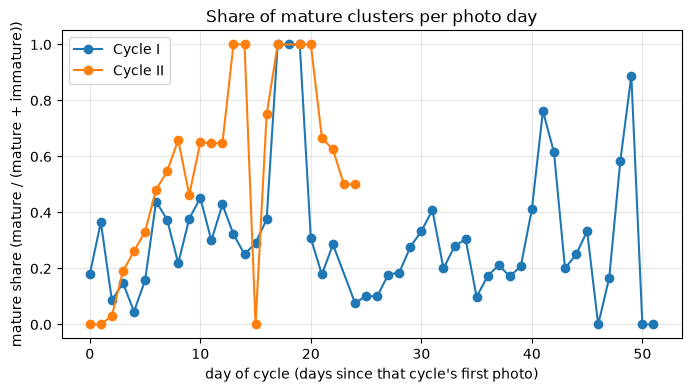

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
for cyc, g in daily.groupby("cycle"):
    ax.plot(g.day_of_cycle, g.mature_share, "o-", label=f"Cycle {cyc}")
ax.set_xlabel("day of cycle (days since that cycle's first photo)")
ax.set_ylabel("mature share (mature / (mature + immature))")
ax.set_title("Share of mature clusters per photo day")
ax.legend(); ax.grid(alpha=.3); plt.show()

## 2 Daily sensor means

Only the **DHT air temperature and DHT humidity** sensors exist in both cycles (Cycle I: ESP8266; Cycle II: ESP1 and ESP2, averaged),
so only they can be compared across cycles. Left out: the Arduino IoT Cloud zip files, the soil/resistive and capacitive moisture sensors, the DS/SHT temperature sensors and the gas sensors.
Sensor columns are `created_at` (ISO with +03:00) and a value that is sometimes text with junk (`61.20` followed by line breaks, `_x000D_`); the junk is stripped and the value converted to a number.
The files have up to 243k rows, so they are opened with openpyxl `read_only`.

**CO2 (eCO2) exists only in Cycle II**, so it cannot be tested across cycles; it is shown as a Cycle II plot only (section 2.3).

In [4]:
def read_sensor(path, sheet):
    wb = openpyxl.load_workbook(path, read_only=True)
    it = wb[sheet].iter_rows(values_only=True)
    next(it)                                           # header
    df = pd.DataFrame([r[:2] for r in it], columns=["created_at", "raw"])
    wb.close()
    n_text = df.raw.map(lambda v: isinstance(v, str)).sum()
    clean = df.raw.map(lambda v: re.sub(r"_x000D_|[\r\n\s]", "", v) if isinstance(v, str) else v)
    df["value"] = pd.to_numeric(clean, errors="coerce")
    df["time"] = pd.to_datetime(df.created_at, utc=True, errors="coerce").dt.tz_convert(TZ)
    n_bad = df.value.isna().sum() + df.time.isna().sum()
    print(f"  {path.name} [{sheet}]: {len(df):,} rows, {n_text:,} text values cleaned, {n_bad} unreadable dropped")
    return df.dropna(subset=["value", "time"])[["time", "value"]]

def daily_of(df, lo, hi, what):
    ok = df.value.between(lo, hi)
    print(f"    {what}: {(~ok).sum()} impossible values dropped (outside {lo}-{hi})")
    df = df[ok]
    return df.groupby(df.time.dt.date).value.agg(["mean", "min", "max", "size"])

print("Cycle I");
t1 = daily_of(read_sensor(SENS / "Cycle I/DHT Temp - ESP8266.xlsx", "ESP8266"), 0, 45, "temperature")
h1 = daily_of(read_sensor(SENS / "Cycle I/DHT Hum - ESP8266.xlsx", "ESP8266"), 0, 100, "humidity")
print("Cycle II (ESP1 and ESP2, averaged)")
t2s, h2s = [], []
for sh in ["ESP1", "ESP2"]:
    t2s.append(daily_of(read_sensor(SENS / "Cycle II/DHT Temp - ESP1-2.xlsx", sh), 0, 45, f"temperature {sh}"))
    h2s.append(daily_of(read_sensor(SENS / "Cycle II/DHT Hum - ESP1-2.xlsx", sh), 0, 100, f"humidity {sh}"))

def avg_sensors(parts):
    cat = pd.concat(parts)
    g = cat.groupby(level=0)
    return pd.DataFrame({"mean": g["mean"].mean(), "min": g["min"].min(), "max": g["max"].max(), "size": g["size"].sum()})
t2, h2 = avg_sensors(t2s), avg_sensors(h2s)

sens = []
for cyc, t, h in [("I", t1, h1), ("II", t2, h2)]:
    s = pd.DataFrame({"temp_mean": t["mean"], "temp_min": t["min"], "temp_max": t["max"],
                      "rh_mean": h["mean"], "n_readings": t["size"]})
    s.index.name = "day"
    s["cycle"] = cyc
    sens.append(s.reset_index())
sens = pd.concat(sens, ignore_index=True)
sens.groupby("cycle").agg(first_day=("day", "min"), last_day=("day", "max"), days=("day", "size"),
                          temp_mean=("temp_mean", "mean"), rh_mean=("rh_mean", "mean"))

Cycle I
  DHT Temp - ESP8266.xlsx [ESP8266]: 243,521 rows, 0 text values cleaned, 0 unreadable dropped
    temperature: 9594 impossible values dropped (outside 0-45)
  DHT Hum - ESP8266.xlsx [ESP8266]: 243,521 rows, 108 text values cleaned, 0 unreadable dropped
    humidity: 0 impossible values dropped (outside 0-100)
Cycle II (ESP1 and ESP2, averaged)
  DHT Temp - ESP1-2.xlsx [ESP1]: 65,509 rows, 0 text values cleaned, 0 unreadable dropped
    temperature ESP1: 0 impossible values dropped (outside 0-45)
  DHT Hum - ESP1-2.xlsx [ESP1]: 65,509 rows, 0 text values cleaned, 0 unreadable dropped
    humidity ESP1: 0 impossible values dropped (outside 0-100)
  DHT Temp - ESP1-2.xlsx [ESP2]: 66,171 rows, 0 text values cleaned, 0 unreadable dropped
    temperature ESP2: 0 impossible values dropped (outside 0-45)
  DHT Hum - ESP1-2.xlsx [ESP2]: 66,171 rows, 0 text values cleaned, 0 unreadable dropped
    humidity ESP2: 0 impossible values dropped (outside 0-100)


,first_day,last_day,days,temp_mean,rh_mean
cycle,,,,,
I,2022-12-26,2023-03-02,62,11.769205,86.113534
II,2023-03-11,2023-05-01,50,16.645319,84.770935


In [5]:
# Mean over the 3 days before each photo day (days d-3, d-2, d-1; at least 2 of the 3 must have data)
def prev3(series, day):
    vals = [series.get(day - pd.Timedelta(days=k)) for k in (1, 2, 3)]
    vals = [v for v in vals if v is not None and not np.isnan(v)]
    return np.mean(vals) if len(vals) >= 2 else np.nan

tm = {c: g.set_index("day").temp_mean for c, g in sens.groupby("cycle")}
rm = {c: g.set_index("day").rh_mean for c, g in sens.groupby("cycle")}
daily["temp_prev3"] = [prev3(tm[c], d) for c, d in zip(daily.cycle, daily.day)]
daily["rh_prev3"] = [prev3(rm[c], d) for c, d in zip(daily.cycle, daily.day)]
daily = daily.merge(sens[["cycle", "day", "temp_mean", "temp_min", "temp_max", "rh_mean", "n_readings"]],
                    on=["cycle", "day"], how="left")

same_day = daily[daily.n_readings.isna()]
print(f"Photo days with no sensor reading on the day itself: {len(same_day)} ({', '.join(f'{c} {d}' for c, d in zip(same_day.cycle, same_day.day))})")
thin = daily[daily.n_readings < 100]
print(f"Photo days with fewer than 100 readings (sensor outage part of the day): {len(thin)}")
no_sensor = daily[daily.temp_prev3.isna() | daily.rh_prev3.isna()]
print("Photo days with no (or too little) sensor data in the 3 days before, dropped from the model:")
print(no_sensor[["cycle", "day", "day_of_cycle", "temp_prev3", "rh_prev3"]].to_string(index=False))
model_df = daily.dropna(subset=["mature_share", "temp_prev3", "rh_prev3"]).reset_index(drop=True)
print(model_df.groupby("cycle").size().rename("days used in the model"))
model_df.round(2)

Photo days with no sensor reading on the day itself: 3 (I 2023-01-10, I 2023-01-13, I 2023-02-18)
Photo days with fewer than 100 readings (sensor outage part of the day): 1
Photo days with no (or too little) sensor data in the 3 days before, dropped from the model:
Empty DataFrame
Columns: [cycle, day, day_of_cycle, temp_prev3, rh_prev3]
Index: []
cycle
I     51
II    24
Name: days used in the model, dtype: int64


,cycle,day,n_photos,n_mature,n_immature,mature_share,day_of_cycle,temp_prev3,rh_prev3,temp_mean,temp_min,temp_max,rh_mean,n_readings
0,I,2023-01-10,5,7,32,0.18,0,13.48,85.25,NaN,NaN,NaN,NaN,NaN
1,I,2023-01-11,4,19,33,0.37,1,12.71,85.53,18.70,16.8,24.5,45.40,1254.0
2,I,2023-01-12,4,5,53,0.09,2,15.64,66.79,16.42,16.1,16.8,36.31,38.0
3,I,2023-01-13,3,8,46,0.15,3,17.56,40.85,NaN,NaN,NaN,NaN,NaN
4,I,2023-01-14,5,5,103,0.05,4,17.56,40.85,10.75,10.4,24.0,83.52,646.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,II,2023-04-24,8,8,0,1.00,20,14.75,96.46,14.89,13.0,16.3,97.27,2900.0
71,II,2023-04-25,9,6,3,0.67,21,14.79,96.65,17.39,14.2,19.8,98.03,2896.0
72,II,2023-04-26,8,5,3,0.62,22,15.66,97.12,17.53,15.4,19.5,97.02,2842.0
73,II,2023-04-27,7,5,5,0.50,23,16.60,97.44,17.08,15.7,18.8,98.62,2854.0


### 2.3 Conditions over time, and CO2 (Cycle II only)

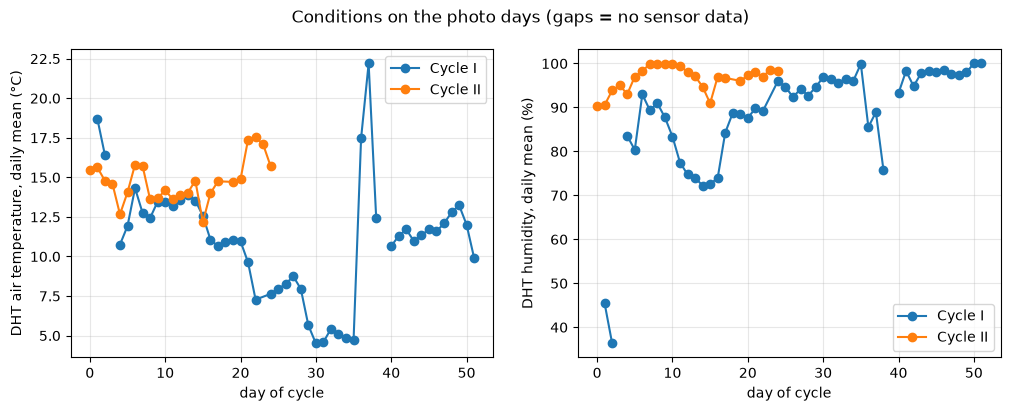

  CSS ECO2 - ESP1.xlsx [ESP1]: 65,509 rows, 0 text values cleaned, 0 unreadable dropped
  SGP ECO2 - ESP3.xlsx [ESP3]: 66,116 rows, 0 text values cleaned, 0 unreadable dropped


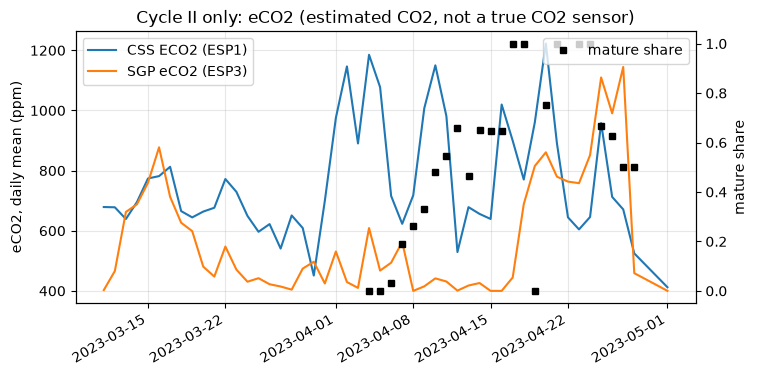

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharex=False)
for cyc, g in daily.groupby("cycle"):
    axs[0].plot(g.day_of_cycle, g.temp_mean, "o-", label=f"Cycle {cyc}")
    axs[1].plot(g.day_of_cycle, g.rh_mean, "o-", label=f"Cycle {cyc}")
axs[0].set_ylabel("DHT air temperature, daily mean (°C)"); axs[1].set_ylabel("DHT humidity, daily mean (%)")
for a in axs: a.set_xlabel("day of cycle"); a.legend(); a.grid(alpha=.3)
fig.suptitle("Conditions on the photo days (gaps = no sensor data)"); plt.show()

# eCO2, Cycle II only (two different sensors; Cycle I has none)
co2 = {"CSS ECO2 (ESP1)": ("Cycle II/CSS ECO2 - ESP1.xlsx", "ESP1"),
       "SGP eCO2 (ESP3)": ("Cycle II/SGP ECO2 - ESP3.xlsx", "ESP3")}
fig, ax = plt.subplots(figsize=(8, 4))
c2 = daily[daily.cycle == "II"]
for name, (f, sh) in co2.items():
    s = read_sensor(SENS / f, sh)
    s = s[s.value.between(300, 10000)]
    dm = s.groupby(s.time.dt.date).value.mean()
    ax.plot(pd.to_datetime(dm.index), dm.values, label=name)
ax.set_ylabel("eCO2, daily mean (ppm)"); ax.set_title("Cycle II only: eCO2 (estimated CO2, not a true CO2 sensor)")
ax2 = ax.twinx()
ax2.plot(pd.to_datetime(c2.day), c2.mature_share, "ks", ms=4, label="mature share")
ax2.set_ylabel("mature share"); ax.legend(loc="upper left"); ax2.legend(loc="upper right")
ax.grid(alpha=.3); fig.autofmt_xdate(); plt.show()

## 3 Model

Target: `mature_share` per day. Two linear regressions:
- **Baseline:** `day_of_cycle` only (clusters get more mature as the cycle goes on).
- **Model:** `day_of_cycle` + `temp_prev3` + `rh_prev3`.

Test: train on one whole cycle, test on the other whole cycle, both directions. Days are never split at random,
because neighbouring days are near-copies of each other and the score would look better than it is.

In [7]:
base_cols = ["day_of_cycle"]
full_cols = ["day_of_cycle", "temp_prev3", "rh_prev3"]
res, coefs = [], []
for tr, te in [("I", "II"), ("II", "I")]:
    A, B = model_df[model_df.cycle == tr], model_df[model_df.cycle == te]
    out = {"train": f"Cycle {tr}", "test": f"Cycle {te}", "n_train": len(A), "n_test": len(B)}
    for name, cols in [("baseline", base_cols), ("model", full_cols)]:
        m = LinearRegression().fit(A[cols], A.mature_share)
        out[f"MAE {name} (pp)"] = 100 * mean_absolute_error(B.mature_share, m.predict(B[cols]))
        if name == "model":
            coefs.append({"trained on": f"Cycle {tr}",
                          "per +1 day of cycle (pp)": 100 * m.coef_[0],
                          "per +1 °C over 3 days (pp)": 100 * m.coef_[1],
                          "per +1 % RH over 3 days (pp)": 100 * m.coef_[2]})
    res.append(out)
res = pd.DataFrame(res)
res["model beats baseline"] = res["MAE model (pp)"] < res["MAE baseline (pp)"]
print("MAE = mean absolute error of mature share on the test cycle, in percentage points (pp). Lower is better.")
display(res.round(1))
print("Always-guess-the-training-mean reference on each test cycle, MAE in pp:",
      {f"test {te}": round(100 * mean_absolute_error(model_df[model_df.cycle == te].mature_share,
                          np.full((model_df.cycle == te).sum(), model_df[model_df.cycle == tr].mature_share.mean())), 1)
       for tr, te in [("I", "II"), ("II", "I")]})

MAE = mean absolute error of mature share on the test cycle, in percentage points (pp). Lower is better.


,train,test,n_train,n_test,MAE baseline (pp),MAE model (pp),model beats baseline
0,Cycle I,Cycle II,51,24,34.0,33.5,True
1,Cycle II,Cycle I,24,51,64.7,110.7,False


Always-guess-the-training-mean reference on each test cycle, MAE in pp: {'test II': 34.2, 'test I': 30.5}


In [8]:
coefs = pd.DataFrame(coefs)
display(coefs.round(2))
for _, r in coefs.iterrows():
    print(f"Trained on {r['trained on']}: +1 °C over 3 days changes mature share by {r['per +1 °C over 3 days (pp)']:+.1f} percentage points; "
          f"+1 % RH over 3 days by {r['per +1 % RH over 3 days (pp)']:+.1f} pp; "
          f"each extra day of cycle by {r['per +1 day of cycle (pp)']:+.1f} pp (other inputs held fixed).")

# How much do the conditions vary at all inside each cycle?
display(model_df.groupby("cycle")[["temp_prev3", "rh_prev3"]].agg(["mean", "std", "min", "max"]).round(2))

,trained on,per +1 day of cycle (pp),per +1 °C over 3 days (pp),per +1 % RH over 3 days (pp)
0,Cycle I,-0.02,0.35,0.01
1,Cycle II,2.77,-14.31,3.09


Trained on Cycle I: +1 °C over 3 days changes mature share by +0.4 percentage points; +1 % RH over 3 days by +0.0 pp; each extra day of cycle by -0.0 pp (other inputs held fixed).
Trained on Cycle II: +1 °C over 3 days changes mature share by -14.3 percentage points; +1 % RH over 3 days by +3.1 pp; each extra day of cycle by +2.8 pp (other inputs held fixed).


temp_prev3                     rh_prev3                     
            mean   std    min    max     mean    std    min    max
cycle                                                             
I          11.27  3.32   4.84  17.56    86.67  12.93  40.85  98.49
II         14.65  0.98  13.41  17.33    96.13   2.79  91.24  99.94

## 4 Verdict

In [9]:
n_win = int(res["model beats baseline"].sum())
for _, r in res.iterrows():
    print(f"{r['train']} -> {r['test']}: baseline MAE {r['MAE baseline (pp)']:.1f} pp, model MAE {r['MAE model (pp)']:.1f} pp "
          f"({'model better' if r['model beats baseline'] else 'baseline as good or better'})")
print()
print({2: "The model beat the baseline in both directions.",
       1: "The model beat the baseline in only one direction, so there is no consistent gain from temperature and humidity.",
       0: "The model did not beat the baseline in either direction: temperature and humidity added nothing that carried over to the other cycle."}[n_win])

Cycle I -> Cycle II: baseline MAE 34.0 pp, model MAE 33.5 pp (model better)
Cycle II -> Cycle I: baseline MAE 64.7 pp, model MAE 110.7 pp (baseline as good or better)

The model beat the baseline in only one direction, so there is no consistent gain from temperature and humidity.


**Plain-language reading.**
- There are only **2 cycles in 1 greenhouse**. Each cycle is one long run of strongly related days, so "train on one, test on the other" is the only fair test, and it rests on just two points of comparison.
- **Conditions vary little within a cycle** (see the spread table above). A small spread gives little to learn from, and temperature and humidity move together with the time of the cycle, so their effect is mixed up with plain ageing of the clusters.
- **The two cameras see different bags** in the two cycles, so a difference between cycles can come from the bags, the light or the labelling, not from the room.
- Conditions in one cycle can lie **outside the range the other cycle taught the model** (e.g. Cycle II was almost always humid and about 14-17 °C), so a model trained on a narrow cycle can predict far off on the wider one.
- The 3-day average is one reasonable choice, not a tested one; other windows were not tried.
- Therefore any effect here is **a hint, not proof**. Use it to decide what to measure next, not to set the room.

**Later step (not in this run):** the *P. ostreatus* rows of `MycoMaterials/cultivation_baseline_ref/mushroom_baseline_ref_2.csv` and the coming NotebookLM file `germini/fruiting_conditions_trials.csv` will be added to compare with published temperature and humidity ranges.

CO2 (eCO2) exists only in Cycle II, so it is not part of the model. The Arduino zip files and the moisture sensors were left out.